# Rain and Traffic in Bangkok — Analysis
**Question:** How does rain change traffic density seen by BMA CCTV cameras, by time of day and weekday vs weekend?

Data: 61,319 images from 100 cameras (25–31 Aug 2026, 06:00–21:00, every 10 min) · vehicles counted with YOLOv8n · rain from the nearest BMA rain gauge (123 stations, hourly).

Input: `data/clean/fact_images.csv` (one row per image), produced by `02_data_engineering/run_all.py`.

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False})
F = pd.read_csv('../data/clean/fact_images.csv', parse_dates=['ts'])
cams = pd.read_csv('../data/cameras.csv')
F['day'] = F.day_type.map({'วันธรรมดา': 'weekday', 'วันหยุด': 'weekend'})
F['period_en'] = F.period.map({'เช้า': '1 morning', 'สาย': '2 late morning', 'บ่าย': '3 afternoon', 'เย็น': '4 evening', 'ค่ำ': '5 night'})
print(len(F), 'images ·', F.cam.nunique(), 'cameras')
F.rain_level.value_counts()

60461 images · 100 cameras


rain_level
dry      56163
light     3399
heavy      899
Name: count, dtype: int64

## 1. Data quality

broken images: 504


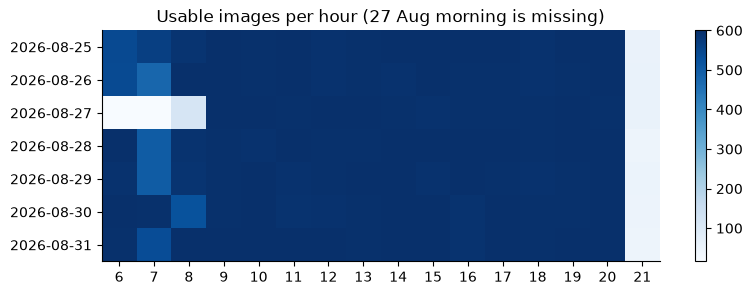

In [2]:
img = pd.read_csv('../data/clean/images.csv')
cov = img[img.is_broken == 0].groupby(['date', 'hour']).size().unstack()
print('broken images:', int(img.is_broken.sum()))
fig, ax = plt.subplots(figsize=(9, 3))
im = ax.imshow(cov, aspect='auto', cmap='Blues')
ax.set_yticks(range(len(cov.index)), cov.index); ax.set_xticks(range(len(cov.columns)), cov.columns)
ax.set_title('Usable images per hour (27 Aug morning is missing)'); plt.colorbar(im); plt.show()

## 2. Normal pattern (dry hours)

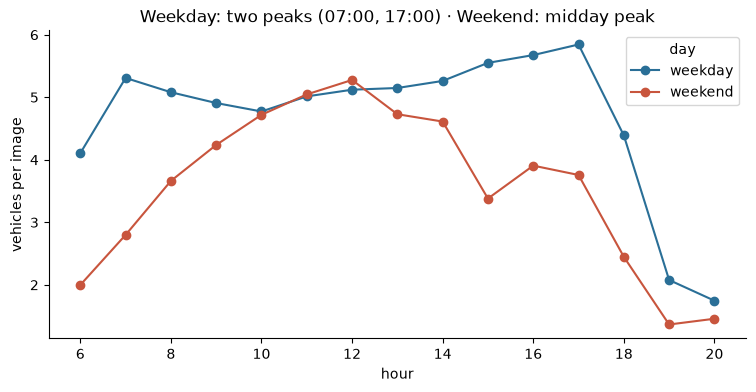

hour,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
day,,,,,,,,,,,,,,,
weekday,4.11,5.31,5.08,4.91,4.77,5.01,5.12,5.15,5.26,5.55,5.67,5.84,4.39,2.08,1.75
weekend,2.00,2.80,3.66,4.24,4.72,5.05,5.28,4.73,4.61,3.38,3.91,3.76,2.45,1.37,1.46


In [3]:
dry = F[F.rain_level == 'dry']
pat = dry.groupby(['hour', 'day']).vehicles.mean().unstack()
ax = pat.plot(marker='o', color={'weekday': '#2a6f97', 'weekend': '#c8553d'})
ax.set_ylabel('vehicles per image'); ax.set_title('Weekday: two peaks (07:00, 17:00) · Weekend: midday peak')
plt.show(); pat.round(2).T

## 3. Rain effect
Congestion index = (vehicles + 1) / (median of same camera × hour × day type in dry hours + 1). 1.00 = normal.
We average on the log scale and get 95% CIs with a cluster bootstrap over cameras (images from one camera are not independent).

In [4]:
rng = np.random.default_rng(7)

def boot(df, reps=1000):
    g = df.assign(l=np.log(df.cong_index)).groupby('cam').l.agg(['sum', 'count'])
    if len(g) < 3:
        return pd.Series({'index': math.exp(g['sum'].sum() / g['count'].sum()), 'lo': np.nan, 'hi': np.nan, 'images': int(g['count'].sum()), 'cams': len(g)})
    s, n = g['sum'].to_numpy(), g['count'].to_numpy()
    k = rng.integers(0, len(g), size=(reps, len(g)))
    m = np.sort(s[k].sum(1) / n[k].sum(1))
    return pd.Series({'index': math.exp(s.sum() / n.sum()), 'lo': math.exp(m[25]), 'hi': math.exp(m[974]), 'images': int(n.sum()), 'cams': len(g)})

M = F[F.baseline_matched == 1]
eff = M.groupby(['day', 'rain_level']).apply(boot).round(3)
eff

index     lo     hi   images   cams
day     rain_level                                     
weekday dry         0.944  0.931  0.956  41005.0  100.0
        heavy       0.679  0.632  0.742     82.0    9.0
        light       0.779  0.734  0.828   1646.0   93.0
weekend dry         0.981  0.967  0.996  15158.0  100.0
        heavy       0.884  0.780  1.021    532.0   67.0
        light       0.970  0.907  1.032    897.0   76.0

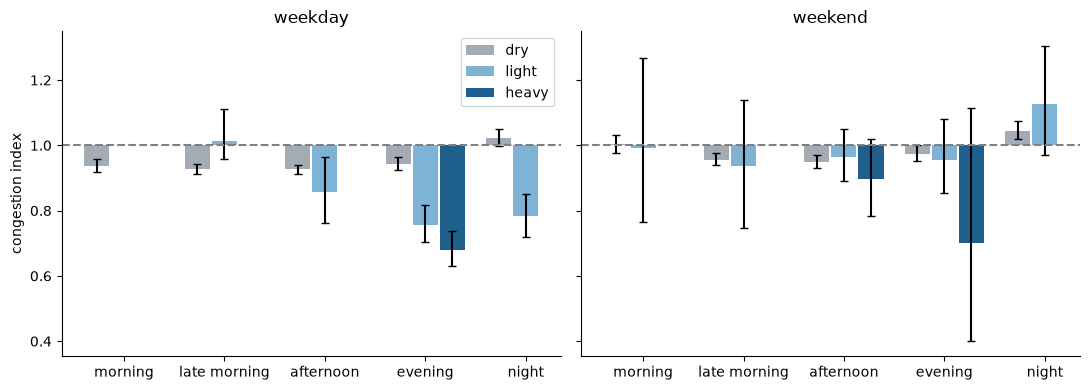

In [5]:
byp = M.groupby(['day', 'period_en', 'rain_level']).apply(boot).round(3).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
colors = {'dry': '#a3abb5', 'light': '#7fb3d5', 'heavy': '#1f5f8b'}
for ax, day in zip(axes, ['weekday', 'weekend']):
    d = byp[byp.day == day]
    periods = sorted(d.period_en.unique())
    for i, lv in enumerate(['dry', 'light', 'heavy']):
        x = d[d.rain_level == lv]
        pos = [periods.index(p) + (i - 1) * 0.27 for p in x.period_en]
        ax.bar(pos, x['index'] - 1, bottom=1, width=0.25, color=colors[lv], label=lv,
               yerr=[x['index'] - x.lo.fillna(x['index']), x.hi.fillna(x['index']) - x['index']], capsize=3)
    ax.axhline(1, ls='--', c='grey'); ax.set_xticks(range(len(periods)), [p[2:] for p in periods]); ax.set_title(day)
axes[0].set_ylabel('congestion index'); axes[0].legend(); plt.tight_layout(); plt.show()

## 4. Mixed-effects model (camera as random effect)

In [6]:
m = F[F.baseline_matched == 1].copy()
m['y'] = np.log(m.vehicles + 1)
model = smf.mixedlm('y ~ C(rain_level, Treatment("dry")) * C(day) + C(hour)', m, groups=m['cam']).fit()
coef = model.params.filter(like='rain_level')
print(model.summary().tables[1].loc[coef.index])
print((np.exp(coef) - 1).round(3).rename('% change vs dry'))

                                                     Coef. Std.Err.       z  \
C(rain_level, Treatment("dry"))[T.heavy]            -0.227    0.068  -3.335   
C(rain_level, Treatment("dry"))[T.light]            -0.152    0.016  -9.684   
C(rain_level, Treatment("dry"))[T.heavy]:C(day)...   0.120    0.073   1.634   
C(rain_level, Treatment("dry"))[T.light]:C(day)...   0.174    0.026   6.625   

                                                    P>|z|  [0.025  0.975]  
C(rain_level, Treatment("dry"))[T.heavy]            0.001  -0.361  -0.094  
C(rain_level, Treatment("dry"))[T.light]            0.000  -0.183  -0.121  
C(rain_level, Treatment("dry"))[T.heavy]:C(day)...  0.102  -0.024   0.264  
C(rain_level, Treatment("dry"))[T.light]:C(day)...  0.000   0.122   0.225  
C(rain_level, Treatment("dry"))[T.heavy]                     -0.203
C(rain_level, Treatment("dry"))[T.light]                     -0.141
C(rain_level, Treatment("dry"))[T.heavy]:C(day)[T.weekend]    0.128
C(rain_level, Treatm

## 5. Is it the traffic or the detector?
Among detected vehicles, YOLO confidence barely changes in rain (0.468 → 0.457 on weekdays), but images are darker (weekday rain falls near dusk) and missed vehicles never show up in confidence. Manual counting of 200 images (`03_data_science/p5_label_sample.py`) is needed before a causal claim.

In [7]:
det = pd.read_csv('../data/clean/detections.csv')[['image_id', 'mean_conf']]
q = F.merge(det, on='image_id')
q.groupby(['day', 'rain_level'])[['mean_conf', 'brightness', 'vehicles']].mean().round(3)

mean_conf  brightness  vehicles
day     rain_level                                 
weekday dry             0.468     115.003     4.692
        heavy           0.416     123.615     4.415
        light           0.457     104.070     3.339
weekend dry             0.471     114.553     3.519
        heavy           0.466     116.465     4.435
        light           0.465     114.511     4.175

## 6. Extra insights

### 6.1 Trucks avoid weekday rush hours

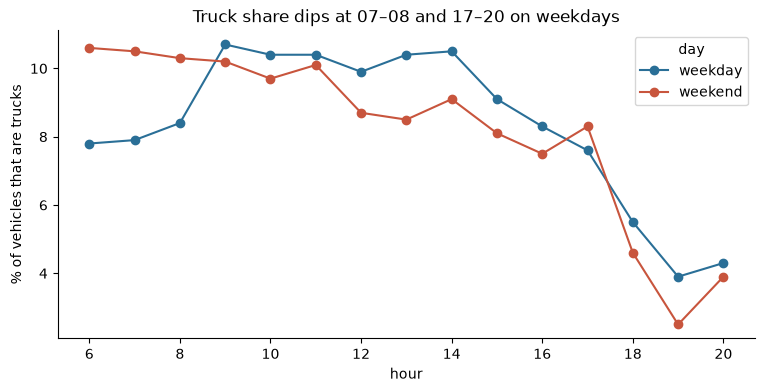

hour,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
day,,,,,,,,,,,,,,,
weekday,7.8,7.9,8.4,10.7,10.4,10.4,9.9,10.4,10.5,9.1,8.3,7.6,5.5,3.9,4.3
weekend,10.6,10.5,10.3,10.2,9.7,10.1,8.7,8.5,9.1,8.1,7.5,8.3,4.6,2.5,3.9


In [8]:
mix = dry.groupby(['day', 'hour'])[['truck', 'bus', 'vehicles']].sum()
share = (mix[['truck', 'bus']].div(mix.vehicles, axis=0) * 100).round(1)
ax = share.truck.unstack(0).plot(marker='o', color={'weekday': '#2a6f97', 'weekend': '#c8553d'})
ax.set_ylabel('% of vehicles that are trucks'); ax.set_title('Truck share dips at 07–08 and 17–20 on weekdays'); plt.show()
share.truck.unstack(0).T

### 6.2 Cameras at the same site agree (data validation)

In [9]:
def hav(a, b, c, d):
    a, b, c, d = map(math.radians, (a, b, c, d))
    return 6371000 * 2 * math.asin(math.sqrt(math.sin((c - a) / 2) ** 2 + math.cos(a) * math.cos(c) * math.sin((d - b) / 2) ** 2))

hr = F.groupby(['cam', 'date', 'hour']).vehicles.mean()
rows = []
cl = cams.to_dict('records')
for i in range(len(cl)):
    for j in range(i + 1, len(cl)):
        dist = hav(cl[i]['lat'], cl[i]['lon'], cl[j]['lat'], cl[j]['lon'])
        if dist < 60:
            x = hr.loc[cl[i]['cam']].to_frame('a').join(hr.loc[cl[j]['cam']].to_frame('b'), how='inner')
            rows.append({'cam_a': cl[i]['cam'], 'cam_b': cl[j]['cam'], 'meters': round(dist), 'hourly_corr': round(x.a.corr(x.b), 2),
                         'dir_a': cl[i]['detail_th'], 'dir_b': cl[j]['detail_th']})
pairs = pd.DataFrame(rows)
print(len(pairs), 'pairs within 60 m · median hourly correlation', pairs.hourly_corr.median())
pairs.sort_values('hourly_corr')

21 pairs within 60 m · median hourly correlation 0.6


,cam_a,cam_b,meters,hourly_corr,dir_a,dir_b
12,176,177,36,0.02,รถมาจากแยกลาดพร้าว-มุ่งหน้า,รถมาจากกำแพงเพชร-มุ่งหน้าไป
4,118,119,18,0.08,รถมาจากแยกสุทธิสาร,รถมาจากแยกห้วยขวาง
6,119,120,34,0.31,รถมาจากแยกห้วยขวาง,รถมาจากซอยลาดพร้าว-64
19,603,604,25,0.33,แยกสีลม-นราธิวาส,ท้ายรถมุ่งหน้าแยกศาลาแดง
10,126,127,18,0.39,รถมาจากแยกรัชโยธิน-มุ่งหน้า,รถมาจากแยกรัชดา-ลาดพร้าว-มุ่
8,123,125,16,0.43,รถมาจากแยกรัชดา-สุทธิสาร,รถมาจากแยกรัชโยธินมุ่งหน้า
17,411,412,2,0.48,แนวถนนพระอาทิตย์-2,แนวถนนพระอาทิตย์-2
14,224,225,22,0.49,รถมาจากแยกรัชโยธิน-มุ่งหน้า,รถมาจากแยกรัชดา-ลาดพร้าว-มุ่
2,70,1361,11,0.51,รถมาจากแยกเทเวศร์มุ่งหน้าไ,ด้านขวารถมาจากแยกบางขุนพรห
13,178,179,17,0.59,รถมาจากแยกสะพานควาย-มุ่งหน้,รถมาจากอนุสาวรีย์ชัยสมรภูม


### 6.3 Morning vs evening peak per camera (direction of flow)

In [10]:
g = dry[dry.day == 'weekday']
ratio = (g[g.hour.isin([7, 8])].groupby('cam').vehicles.mean() / g[g.hour.isin([16, 17])].groupby('cam').vehicles.mean()).rename('am_pm_ratio')
t = cams.set_index('cam').join(ratio)
print('evening-heavy (ratio < 0.77):', int((t.am_pm_ratio < 1 / 1.3).sum()), '· morning-heavy (> 1.3):', int((t.am_pm_ratio > 1.3).sum()))
t.sort_values('am_pm_ratio')[['name_th', 'detail_th', 'am_pm_ratio']].round(2).iloc[list(range(5)) + list(range(-5, 0))]

evening-heavy (ratio < 0.77): 38 · morning-heavy (> 1.3): 11


,name_th,detail_th,am_pm_ratio
cam,,,
1076,สะพานลอยใกล้ซอยเทอดไท-21-ถนนร,รถมาจากแยกตากสิน-มุ่งหน้าไป,0.21
170,สะพานลอยใกล้โรงพยาบาลวุฒิส,รถมาจากอนุสาวรีย์ชัยสมรภูม,0.23
82,สะพานลอยใกล้ซอยราชปรารภ-3-ถน,รถมาจากแยกหมอเหล็ง-มุ่งหน้า,0.23
196,สะพานลอยหน้าแมคโคร-ถนนนราธิ,รถมาจากแยกสาทร-นราธิวาส-มุ่ง,0.33
556,แยกวชิระ,แยกวชิระ,0.42
127,สะพานลอยซอยรัชดาภิเษก-30-ใกล้,รถมาจากแยกรัชดา-ลาดพร้าว-มุ่,1.74
158,สะพานลอยใกล้ซอยเจริญนคร-46,ถนนเจริญนคร-ขาเข้า,1.76
225,สะพานลอยใกล้ศาลอาญา-ถนนรัชด,รถมาจากแยกรัชดา-ลาดพร้าว-มุ่,2.12
212,สะพานลอยใกล้บิ๊กซีรัชดา-ถนน,รถมาจากแยกเทียมร่วมมิตร-มุ่,2.26


### 6.4 Does the effect last after the rain stops?

In [11]:
h = F.groupby(['cam', 'date', 'hour']).agg(rl=('rain_level', 'first'), li=('cong_index', lambda s: np.log(s).mean()), bm=('baseline_matched', 'min')).reset_index()
h['prev'] = h.groupby(['cam', 'date']).rl.shift(1)
after = h[(h.rl == 'dry') & h.prev.isin(['light', 'heavy']) & (h.bm == 1)]
normal = h[(h.rl == 'dry') & (h.prev == 'dry') & (h.bm == 1)]
pd.Series({'first dry hour after rain': math.exp(after.li.mean()), 'normal dry hour': math.exp(normal.li.mean()), 'n after': len(after)}).round(3)

first dry hour after rain      0.918
normal dry hour                0.954
n after                      362.000
dtype: float64

### 6.5 Possibly frozen cameras

In [12]:
d = img[img.is_broken == 0].merge(pd.read_csv('../data/clean/detections.csv'), on='image_id').sort_values(['cam', 'ts'])
d['same_as_prev'] = (d.groupby('cam').occupancy.diff() == 0) & (d.groupby('cam').vehicles.diff() == 0) & (d.vehicles > 0)
d.groupby('cam').same_as_prev.sum().sort_values(ascending=False).head(6)

cam
150    124
939     96
938     95
395     68
206     10
595      7
Name: same_as_prev, dtype: int64

### 6.6 Flood-prone spots: does rain hurt more where flooding is not fixed yet?
Two extra BMA sources (scraped by `s8_bma_road_flood.py` and `s9_bma_flood_risk.py`):
- **737 flood-risk points** from BMA Open Data with fix status (fixed / partly fixed / not fixed yet)
- **road flood sensors** (water depth on the road, hourly for 25–31 Aug)

Each camera is grouped by the flood-risk points within 500 m (`p6_flood_join.py`).

In [13]:
ctx = pd.read_csv('../data/clean/camera_flood_context.csv')
ff = pd.read_csv('../data/clean/fact_images_flood.csv')
print(ctx.flood_group.value_counts().to_dict())
print('images with a flood sensor within 1 km:', int(ff.flood_cm.notna().sum()), '· images with water on the road:', int(ff.road_flooded.sum()))
fl = pd.read_csv('../data/clean/bma_road_flood_hourly.csv')
fl[fl.flood_cm > 0].groupby(['sensor', 'name']).flood_cm.agg(['count', 'min', 'max'])

{'not_near': 51, 'near_fixed_only': 28, 'near_unfixed': 21}
images with a flood sensor within 1 km: 44751 · images with water on the road: 0


,,count,min,max
sensor,name,,,
FL.RTW.02,ถ.เพชรบุรี (ดอนบอสโก),33,4.6,5.1


In [14]:
ff['day'] = ff.day_type.map({'วันธรรมดา': 'weekday', 'วันหยุด': 'weekend'})
fm = ff[ff.baseline_matched == 1]
grp = fm.groupby(['day', 'flood_group', 'rain_level']).apply(boot).round(3)
grp

index     lo     hi   images  cams
day     flood_group     rain_level                                    
weekday near_fixed_only dry         0.953  0.929  0.980  11528.0  28.0
                        heavy       0.655    NaN    NaN     12.0   1.0
                        light       0.848  0.734  0.961    438.0  27.0
        near_unfixed    dry         0.938  0.918  0.957   8632.0  21.0
                        heavy       0.738  0.572  0.808     24.0   3.0
                        light       0.843  0.763  0.924    312.0  20.0
        not_near        dry         0.941  0.925  0.956  20845.0  51.0
                        heavy       0.656  0.603  0.729     46.0   5.0
                        light       0.726  0.682  0.779    896.0  46.0
weekend near_fixed_only dry         0.971  0.949  0.999   4360.0  28.0
                        heavy       0.887  0.714  1.131    138.0  20.0
                        light       1.020  0.934  1.110    270.0  22.0
        near_unfixed    dry         0.979  0.956  1.005   3187.0  21.0
                        heavy       0.743  0.603  0.887    118.0  15.0
                        light       1.038  0.906  1.223    198.0  15.0
        not_near        dry         0.987  0.964  1.009   7611.0  51.0
                        heavy       0.951  0.768  1.171    276.0  32.0
                        light       0.911  0.829  1.007    429.0  39.0

In [15]:
from scipy import stats
pc = fm.assign(l=np.log(fm.cong_index)).groupby(['cam', 'rain_level']).l.mean().unstack()
pc['rain_effect'] = np.exp(pc[['light', 'heavy']].mean(axis=1)) - np.exp(pc['dry'])
pc = pc.join(fm[fm.rain_level != 'dry'].groupby('cam').size().rename('n_wet')).join(ctx.set_index('cam'))
pc = pc[pc.n_wet >= 6]
print(pc.groupby('flood_group').rain_effect.agg(['median', 'count']).round(3))
print('near not-fixed vs not near (Mann-Whitney):', stats.mannwhitneyu(pc[pc.flood_group == 'near_unfixed'].rain_effect, pc[pc.flood_group == 'not_near'].rain_effect).pvalue.round(3))
print('distance to nearest risk point vs effect (Spearman):', round(stats.spearmanr(pc.nearest_risk_m, pc.rain_effect).statistic, 3))

                 median  count
flood_group                   
near_fixed_only  -0.080     27
near_unfixed     -0.163     21
not_near         -0.120     49
near not-fixed vs not near (Mann-Whitney): 0.701
distance to nearest risk point vs effect (Spearman): -0.035


## 8. General insights (not about rain)
All use dry hours only, so rain does not mix in.

### 8.1 Weekend vs weekday by place (09:00–14:59)

In [16]:
mid = dry[dry.hour.between(9, 14)].groupby(['cam', 'day']).vehicles.mean().unstack()
mid['weekend_ratio'] = mid.weekend / mid.weekday
mid = mid.join(cams.set_index('cam')[['name_th']])
print('median weekend/weekday ratio:', round(mid.weekend_ratio.median(), 2))
pd.concat([mid.sort_values('weekend_ratio', ascending=False).head(6), mid.sort_values('weekend_ratio').head(6)])[['name_th', 'weekday', 'weekend', 'weekend_ratio']].round(2)

median weekend/weekday ratio: 0.98


,name_th,weekday,weekend,weekend_ratio
cam,,,,
176,สะพานลอยหน้าสวนจตุจักร-ถนนพ,1.95,3.12,1.60
301,แยกอู่ทองนอก,4.27,5.70,1.33
88,แยกจันทน์-สาธุประดิษฐ์-ด้านถ,2.20,2.83,1.29
1195,แยกบุคคโล(ถนนมไหสวรรค์ขาเข้,7.93,9.86,1.24
125,แยกรัชดา-ลาดพร้าว-ด้านถนนลาด,3.22,3.95,1.23
1362,แยกสามเสน,1.24,1.52,1.22
206,สะพานลอยใกล้ซอยนราธิวาสราช,1.38,0.47,0.34
277,ทางแยกอ.ชัยสมรภูมิ,14.45,9.22,0.64
939,TF-KP-04-แยกมหาดไทย,1.61,1.08,0.67


### 8.2 Four types of daily traffic profile (k-means on weekday hourly shape)

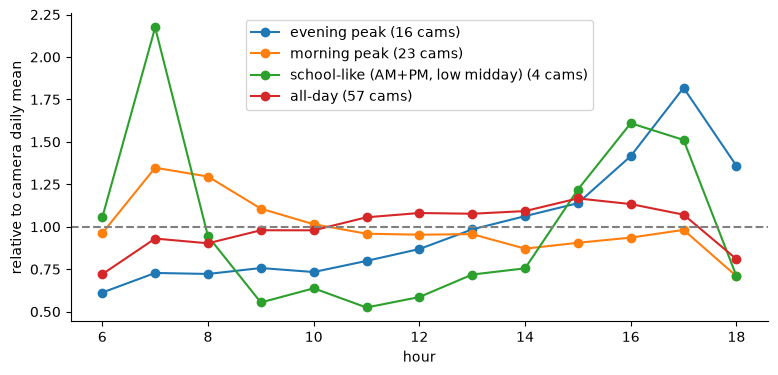

profile
all-day                            [แยกสะพานแดง-ด้านถนนทหาร, แยกบุคคโล-ด้านถนนเจร...
evening peak                       [สะพานลอยใกล้ซอยราชปรารภ-3-ถน, แยกรัชดา-สุทธิส...
morning peak                       [ใกล้ซอยราชวิถี-6-ถนนราชวิถี, แยกรัชดา-ราชพฤกษ...
school-like (AM+PM, low midday)    [ตรงข้ามพระตำหนักจิตรลดารโห, สะพานลอยใกล้-รร.เ...
Name: name_th, dtype: object

In [17]:
from scipy.cluster.vq import kmeans2
wdd = dry[(dry.day == 'weekday') & dry.hour.between(6, 18)]
prof = wdd.groupby(['cam', 'hour']).vehicles.mean().unstack()
Z = prof.div(prof.mean(axis=1), axis=0).fillna(1)
best = None
for seed in range(20):
    cen, lab = kmeans2(Z.values, 4, seed=seed, minit='++')
    inertia = ((Z.values - cen[lab]) ** 2).sum()
    if best is None or inertia < best[0]:
        best = (inertia, cen, lab)
_, cen, lab = best
names = {}
for k in range(4):
    am, mid_, pm = cen[k][1:3].mean(), cen[k][5:9].mean(), cen[k][10:12].mean()
    names[k] = 'school-like (AM+PM, low midday)' if am > 1.3 and pm > 1.3 else 'morning peak' if am > 1.2 else 'evening peak' if pm > 1.3 else 'all-day'
Z['profile'] = [names[k] for k in lab]
fig, ax = plt.subplots()
for k in range(4):
    ax.plot(prof.columns, cen[k], marker='o', label='%s (%d cams)' % (names[k], (lab == k).sum()))
ax.axhline(1, ls='--', c='grey'); ax.set_xlabel('hour'); ax.set_ylabel('relative to camera daily mean'); ax.legend(); plt.show()
Z[['profile']].join(cams.set_index('cam').name_th).groupby('profile').name_th.apply(lambda s: list(s)[:6])

### 8.3 When is each camera busiest? Day-of-week pattern

In [18]:
peak = wdd.groupby(['cam', 'hour']).vehicles.mean().unstack().idxmax(axis=1)
print('cameras by weekday peak hour:', peak.value_counts().sort_index().to_dict())
dow = dry.assign(dow=dry.ts.dt.day_name())
print('16:00–18:59 vehicles per image by day:', dow[dow.hour.between(16, 18)].groupby('dow').vehicles.mean().round(2).to_dict())
print('daily mean (dry):', dry.groupby('date').vehicles.mean().round(2).to_dict())

cameras by weekday peak hour: {6: 3, 7: 15, 8: 7, 9: 3, 10: 3, 11: 5, 12: 4, 13: 6, 14: 5, 15: 7, 16: 15, 17: 25, 18: 2}
16:00–18:59 vehicles per image by day: {'Friday': 5.85, 'Monday': 4.35, 'Saturday': 3.37, 'Sunday': 3.11, 'Thursday': 5.23, 'Tuesday': 5.23, 'Wednesday': 5.48}
daily mean (dry): {'2026-08-25': 4.64, '2026-08-26': 4.79, '2026-08-27': 4.63, '2026-08-28': 4.84, '2026-08-29': 3.62, '2026-08-30': 3.43, '2026-08-31': 4.53}


### 8.4 Busiest areas (district of the nearest rain gauge, ≥ 4 cameras)

In [19]:
st = pd.read_csv('../data/clean/bma_rain_stations.csv')
cams['district'] = [st.district.iloc[((st.lat - r.lat) ** 2 + ((st.lon - r.lon) * 0.97) ** 2).idxmin()] for r in cams.itertuples()]
area = cams.set_index('cam').join(dry.groupby('cam').vehicles.mean().rename('veh')).groupby('district').agg(cams=('veh', 'size'), vehicles=('veh', 'mean'))
area[area.cams >= 4].sort_values('vehicles', ascending=False).round(2)

,cams,vehicles
district,,
ราชเทวี,5,6.77
ธนบุรี,5,5.78
ป้อมปราบฯ,7,5.23
บางรัก,5,5.19
ยานนาวา,4,5.11
พญาไท,5,4.98
ห้วยขวาง,9,4.60
ปทุมวัน,5,4.04
จตุจักร,13,3.96


### 8.5 Vehicle mix by place
Note: the COCO class *truck* also catches pickups, and some class labels can be wrong — check the top cameras by eye.

In [20]:
mix = F.groupby('cam')[['car', 'motorcycle', 'bus', 'truck', 'vehicles']].sum().join(cams.set_index('cam').name_th)
for k in ['bus', 'motorcycle', 'truck']:
    mix[k + '_%'] = (mix[k] / mix.vehicles * 100).round(1)
pd.concat({k: mix.sort_values(k + '_%', ascending=False).head(4)[['name_th', k + '_%']].reset_index(drop=True) for k in ['bus', 'motorcycle', 'truck']}, axis=1)

bus                          motorcycle  \
                         name_th bus_%                       name_th   
0    สะพานลอยหน้าสวนจตุจักร-ถนนพ  70.8     BR-05-01-แยกสีลม-นราธิวาส   
1  สะพานลอยใกล้ซอยเทอดไท-21-ถนนร  44.5            ทางแยกมิตรสัมพันธ์   
2    สะพานลอยหน้าสวนจตุจักร-ถนนพ  36.7                    แยกเทเวศน์   
3    สะพานลอยใกล้บิ๊กซีรัชดา-ถนน  36.2  แยกรัชดา-สุทธิสาร-ด้านถนนสุท   

                                        truck          
  motorcycle_%                        name_th truck_%  
0         35.8  สะพานลอยซอยรัชดาภิเษก-30-ใกล้    38.6  
1         26.4     ตรงข้ามพระตำหนักจิตรลดารโห    32.6  
2         23.2   แยกรัชดา-ลาดพร้าว-ด้านถนนลาด    28.1  
3         19.3     TF-KP-03-รามคำแหง-พระราม-9    28.0

### 8.6 How predictable is each camera? (same hour, different days)

In [21]:
v = wdd.groupby(['cam', 'date', 'hour']).vehicles.mean().groupby(['cam', 'hour']).agg(['mean', 'std'])
cv = (v['std'] / v['mean']).groupby('cam').median().rename('cv')
print('median coefficient of variation:', round(cv.median(), 2))
cams.set_index('cam').join(cv).sort_values('cv', ascending=False)[['name_th', 'cv']].head(5).round(2)

median coefficient of variation: 0.28


,name_th,cv
cam,,
170,สะพานลอยใกล้โรงพยาบาลวุฒิส,0.79
1060,หน้าโรงเรียนสายปัญญา-ถนนกรุ,0.55
239,สะพานลอยใกล้-รร.เตรียมอุดมศึ,0.54
556,แยกวชิระ,0.53
1815,แยกพระราม-9,0.53


## 9. Summary
- Chatuchak (weekend market) has 60% more traffic on weekends; CBD and government areas drop 30–66%.
- Four daily profiles: all-day (57 cams), morning peak (23), evening peak (16), school-like double peak with a midday dip (4, near Chitralada and Triam Udom schools).
- Weekday traffic peaks at 07:00 and 17:00; weekend peaks at noon.
- Rain falls only in the afternoon/evening in this week; rain is patchy (≤ 38% of gauges at once).
- Weekday rain: fewer vehicles detected (light −22%, heavy −32%); weekend: small, not significant.
- Mixed-effects model (camera random effect, hour fixed effects): weekday light rain −14%, heavy −20%; weekend light ≈ +2%.
- Detection error in dark/rainy images is not ruled out yet → verify with manual labels.
- Trucks drop to ~8% of traffic at weekday rush hours vs ~10.5% midday (consistent with Bangkok truck-restriction hours).
- Co-located cameras agree (median r ≈ 0.6) except pairs facing different directions.
- Cameras 150, 939, 938, 395 repeat identical detections → possibly frozen images; check before using them.
- Road flood sensors near 76 cameras recorded no water on the road during 25–31 Aug → effects in this week come from rain, not road flooding.
- Cameras near flood-risk points that are not fixed yet do not show a stronger rain effect overall (Mann-Whitney p ≈ 0.70); only weekend heavy rain shows fewer vehicles there (0.74 vs 0.95), a hint that drivers avoid flood-prone roads.